PART A

In [1]:
!pip install scikit-learn Pillow numpy pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Define Sample Text Data (our "corpus")
documents = [
    "The sun is shining today.",
    "The weather is good, the sun is great.",
    "A sunny day is a wonderful day."
]

print("--- Raw Text Documents ---")
for i, doc in enumerate(documents):
    print(f"Doc {i+1}: {doc}")

--- Raw Text Documents ---
Doc 1: The sun is shining today.
Doc 2: The weather is good, the sun is great.
Doc 3: A sunny day is a wonderful day.


In [3]:
# 2. Apply Feature Engineering: CountVectorizer (Bag-of-Words)
#    CountVectorizer performs tokenization AND vocabulary building in one step.
vectorizer = CountVectorizer()

# fit_transform learns the vocabulary and converts the documents into feature vectors
X_text = vectorizer.fit_transform(documents)

# 3. Analyze the Results
feature_names = vectorizer.get_feature_names_out()
text_matrix = X_text.toarray()

print("--- Bag-of-Words (BoW) Transformation ---")
print(f"Vocabulary (Features): {feature_names}")
print(f"Shape of Feature Matrix: {text_matrix.shape}   (documents x unique terms)")

--- Bag-of-Words (BoW) Transformation ---
Vocabulary (Features): ['day' 'good' 'great' 'is' 'shining' 'sun' 'sunny' 'the' 'today' 'weather'
 'wonderful']
Shape of Feature Matrix: (3, 11)   (documents x unique terms)


In [4]:
# A DataFrame view, purely so the matrix is readable
df_text = pd.DataFrame(text_matrix, columns=feature_names,
                       index=[f"Doc {i+1}" for i in range(len(documents))])

print("BoW Numerical Feature Matrix (Machine Understandable Format):\n")
display(df_text)

BoW Numerical Feature Matrix (Machine Understandable Format):



,day,good,great,is,shining,sun,sunny,the,today,weather,wonderful
Doc 1,0,0,0,1,1,1,0,1,1,0,0
Doc 2,0,1,1,2,0,1,0,2,0,1,0
Doc 3,2,0,0,1,0,0,1,0,0,0,1


In [5]:
# Prove the two silent decisions to yourself rather than taking them on trust.

print("Is 'a' in the vocabulary? ", 'a' in feature_names)
print("Is 'the' in the vocabulary?", 'the' in feature_names)
print()
print("Default token pattern :", vectorizer.token_pattern)
print("Lowercase enabled     :", vectorizer.lowercase)
print()
print("The token pattern requires 2+ word characters, which is why 'a' is dropped.")

Is 'a' in the vocabulary?  False
Is 'the' in the vocabulary? True

Default token pattern : (?u)\b\w\w+\b
Lowercase enabled     : True

The token pattern requires 2+ word characters, which is why 'a' is dropped.


In [6]:
# Sparsity: how much of this matrix is zero? This is the defining property of BoW.
total_cells = text_matrix.size
zero_cells = (text_matrix == 0).sum()

print(f"Matrix cells : {total_cells}")
print(f"Zero cells   : {zero_cells}")
print(f"Sparsity     : {zero_cells / total_cells:.1%}")
print()
print("With a real corpus of 20,000 documents this figure exceeds 99%,")
print("which is why scikit-learn returns a SPARSE matrix, not a dense array.")
print("Type returned by fit_transform:", type(X_text))

Matrix cells : 33
Zero cells   : 18
Sparsity     : 54.5%

With a real corpus of 20,000 documents this figure exceeds 99%,
which is why scikit-learn returns a SPARSE matrix, not a dense array.
Type returned by fit_transform: <class 'scipy.sparse._csr.csr_matrix'>


Part B — Feature engineering for image data

In [8]:
%pip install opencv-python


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 1.2 MB/s eta 0:00:37
    --------------------------------------- 1.0/44.0 MB 1.6 MB/s eta 0:00:28
   - -------------------------------------- 1.8/44.0 MB 2.2 MB/s eta 0:00:20
   -- ------------------------------------- 3.1/44.0 MB 3.1 MB/s eta 0:00:14
   --- ------------------------------------ 3.9/44.0 MB 3.6 MB/s eta 0:00:12
   ---- ----------------------------------- 4.7/44.0 MB 3.3 MB/s eta 0:00:12
   ---- ----------------------------------- 5.2/44.0 MB 3.7 MB/s eta 0:00:11
   ---- ----------------------------------- 5.2/44.0 MB 3.7 MB/s eta 0:00:11
   ------- -------------------------------- 7.9/44.0 MB 4.0 MB/s eta 0:00:10
   ------- --------

In [9]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

In [10]:
image_file_path = 'pic.jpeg'
print("Working directory:", os.getcwd())
print("File found:", os.path.exists(image_file_path))   # must say True

original_image = Image.open(image_file_path).convert('RGB')
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print("Original shape (H, W, C):", original_image_array.shape)
print("Total features in RGB:", h * w * c)

Working directory: C:\Users\safas
File found: True
Original shape (H, W, C): (1256, 736, 3)
Total features in RGB: 2773248


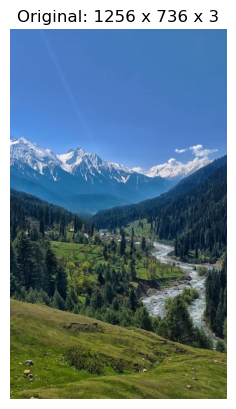

In [11]:
plt.imshow(original_image_array)
plt.title(f"Original: {h} x {w} x {c}")
plt.axis('off')
plt.show()

Resized shape: (109, 64, 3)
Features after resize: 20928


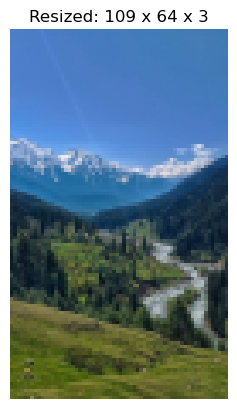

In [12]:
target_w = 64
target_h = int(round(h * target_w / w))   # keeps aspect ratio; use target_h = 64 if your lab wants 64x64

resized = cv2.resize(original_image_array, (target_w, target_h), interpolation=cv2.INTER_AREA)
print("Resized shape:", resized.shape)    # (target_h, 64, 3)
print("Features after resize:", resized.size)

plt.imshow(resized)
plt.title(f"Resized: {target_h} x {target_w} x 3")
plt.axis('off')
plt.show()

Grayscale shape: (109, 64)
Value range: 15 to 237
Features after grayscale: 6976


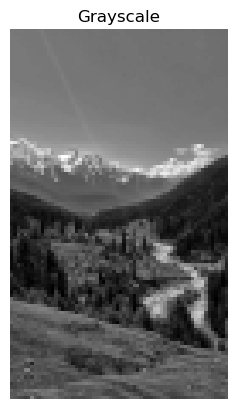

In [13]:
gray = cv2.cvtColor(resized, cv2.COLOR_RGB2GRAY)
print("Grayscale shape:", gray.shape)     # (target_h, 64), the channel axis is gone
print("Value range:", gray.min(), "to", gray.max())
print("Features after grayscale:", gray.size)

plt.imshow(gray, cmap='gray')
plt.title("Grayscale")
plt.axis('off')
plt.show()

In [14]:
feature_vector = gray.flatten()           # row-major order
print("Feature vector shape:", feature_vector.shape)
print("Length:", feature_vector.size, "= H*W =", target_h * target_w)
print("First 10 values:", feature_vector[:10])

Feature vector shape: (6976,)
Length: 6976 = H*W = 6976
First 10 values: [119 119 119 119 118 118 118 118 120 122]


In [15]:
print(f"Original RGB : {h} x {w} x 3  -> {h*w*3} values")
print(f"Resized RGB  : {target_h} x {target_w} x 3  -> {target_h*target_w*3} values")
print(f"Grayscale    : {target_h} x {target_w}  -> {target_h*target_w} values")
print(f"Flattened    : vector of length {feature_vector.size}")

Original RGB : 1256 x 736 x 3  -> 2773248 values
Resized RGB  : 109 x 64 x 3  -> 20928 values
Grayscale    : 109 x 64  -> 6976 values
Flattened    : vector of length 6976


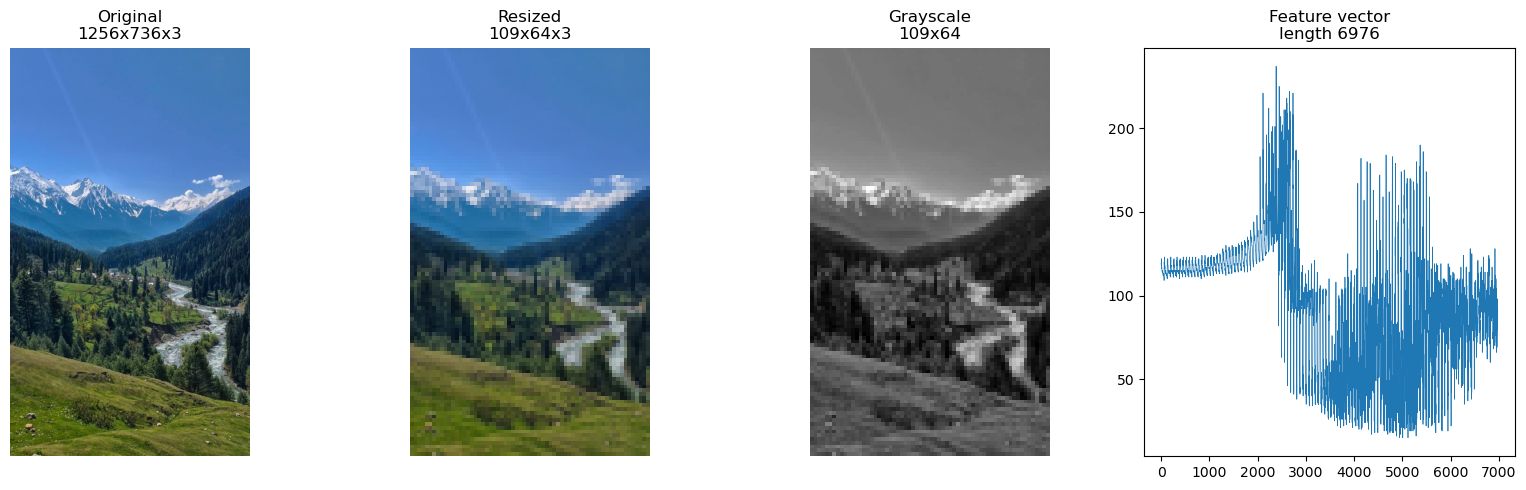

In [16]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))
ax[0].imshow(original_image_array);   ax[0].set_title(f"Original\n{h}x{w}x3")
ax[1].imshow(resized);                ax[1].set_title(f"Resized\n{target_h}x{target_w}x3")
ax[2].imshow(gray, cmap='gray');      ax[2].set_title(f"Grayscale\n{target_h}x{target_w}")
ax[3].plot(feature_vector, lw=0.5);   ax[3].set_title(f"Feature vector\nlength {feature_vector.size}")
for a in ax[:3]:
    a.axis('off')
plt.tight_layout()
plt.show()

In [17]:
r, col = 10, 20
print(gray[r, col] == feature_vector[r * target_w + col])     # True: index = r*W + c
print("Vertical neighbour is", target_w, "positions away in the vector")

reconstructed = feature_vector.reshape(target_h, target_w)
print("Reconstruction identical:", np.array_equal(reconstructed, gray))   # True

True
Vertical neighbour is 64 positions away in the vector
Reconstruction identical: True
